# PHYS3116: The Faber–Jackson relation in SAMI

How does a galaxy's stellar mass relate to the motion of its stars? That is the question I am following here, using the SAMI catalogues and the Faber–Jackson relation.

I start with the tables, check which galaxies can be compared, and then work through the plots and fits. Before interpreting a slope, I also want to see how it responds to changes in morphology, aperture and the flag selection. Each numbered step explains the choice before the code carries it out.

Run from the first cell, with `data/` and `results/` beside this notebook. The analysis reads the supplied local CSVs. The programming methods come from Tutorials 1, 2 and 4 and Spotted Python Weeks 2–4; `METHODS.md` maps them to the examples. Some analysis steps apply those methods to this question, as explained below.

This follows **Option 2 of the 2026 PHYS3116 brief**. The separately supplied 2025 PHYS2116 brief is for a different assessment.


## 1) Start with the data

First, I load the four catalogues and look at their columns. This is a small check that matters: the CSVs use lower-case names, even where the schemas use capitals. `pd.read_csv` brings each file into a table, and the printed counts show what we are starting with.

*Tutorial link: Tutorial 2, Pandas; Tutorial 4, imports and linear curve fitting.*


In [1]:
print('\n1) Start with the data')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Start with the four local tables, then check their sizes and column names.
gama_data = pd.read_csv('data/InputCatGAMADR3(3).csv')
cluster_data = pd.read_csv('data/samiDR3InputCatClusters(3).csv')
kinematic_data = pd.read_csv('data/samiDR3StelKin(3).csv')
morphology_data = pd.read_csv('data/samiDR3VisualMorphology(3).csv')

print('GAMA catalogue rows:', len(gama_data))
print('Cluster catalogue rows:', len(cluster_data))
print('Kinematic observation rows:', len(kinematic_data))
print('Morphology catalogue rows:', len(morphology_data))
print(gama_data.columns)
print(kinematic_data.columns)
print(morphology_data.head())



1) Start with the data
GAMA catalogue rows: 5536
Cluster catalogue rows: 1433
Kinematic observation rows: 3426
Morphology catalogue rows: 3068
Index(['Unnamed: 0', 'catid', 'ra_obj', 'dec_obj', 'ra_ifu', 'dec_ifu',
       'r_petro', 'r_auto', 'z_tonry', 'z_spec', 'm_r', 'r_e', 'mu_within_1re',
       'mu_1re', 'mu_2re', 'ellip', 'pa', 'mstar', 'g_i', 'a_g', 'surv_sami',
       'bad_class'],
      dtype='object')
Index(['Unnamed: 0', 'cubeid', 'cubeidpub', 'cubename', 'catid', 'pa_stelkin',
       'pa_stelkin_err', 'sigma_re', 'sigma_re_err', 'sigma_3kpc_round',
       'sigma_3kpc_round_err', 'sigma_1_4_arcsecond',
       'sigma_1_4_arcsecond_err', 'sigma_2_arcsecond', 'sigma_2_arcsecond_err',
       'sigma_3_arcsecond', 'sigma_3_arcsecond_err', 'sigma_4_arcsecond',
       'sigma_4_arcsecond_err', 'aper_corr_flag', 'rmax_aper_corr',
       'lambdar_re', 'lambdar_re_err', 'lambdar_max', 'lambdar_max_err',
       'vsigma_re', 'vsigma_re_err', 'vsigma_max', 'vsigma_max_err',
       'mean_

## 2) Make sure the columns mean what I think they mean

Before choosing galaxies, I want the quantities and units clear.

| Column | What it tells us |
|---|---|
| `catid` | Galaxy ID used to match the tables |
| `cubeidpub` | ID of a particular observation |
| `mstar` | Already $\log_{10}(M_\star/M_\odot)$, in dex |
| `m_r` | Absolute magnitude in the **r band** |
| `sigma_re` | Dispersion within the Sérsic effective-radius aperture, in km/s |
| `sigma_re_err` | Reported one-sigma uncertainty on that dispersion, in km/s |
| `sigma_3kpc_round` | Dispersion within the 3 kpc aperture, in km/s |
| `type` | Visual morphology code |
| `bad_class` | Bad/problem-object flag; the supplied schema does not define the individual codes |

The morphology codes are 0 = E, 0.5 = E/S0, 1 = S0, 1.5 = S0/early spiral, 2 = early spiral, 2.5 = early/late spiral, 3 = late spiral, 5 = uncertain, and −9 = no agreement.

For the main sample, I use **E and E/S0: codes 0 and 0.5**, following Tutorial 4's exercise categories. E/S0 is a transitional category, so I also check strict ellipticals on their own later. Writing the two categories explicitly avoids accidentally keeping code −9 with a condition such as `type < 1`.

I use `bad_class == 0` as a **working selection rule**. Its meaning still needs confirmation from the catalogue's flag definitions, including the meaning of zero. The later comparison with all flag codes shows how much this choice changes the fit; it cannot tell us what the codes mean.

`aper_corr_flag` refers to corrections for $V/\sigma$ and $\lambda_R$, so I do not use it as a general dispersion-quality flag.

The next cell converts the numerical columns. Entries that cannot be converted become `NaN`, which makes them available for the missing-value checks.


In [2]:
print('\n2) Get the numerical columns ready')

# Get the numerical columns ready for the checks below.
# Unreadable entries become NaN so they can be picked up as missing.
for column in ['catid', 'mstar', 'm_r', 'bad_class']:
    gama_data[column] = pd.to_numeric(gama_data[column], errors='coerce')
    cluster_data[column] = pd.to_numeric(cluster_data[column], errors='coerce')

for column in ['catid', 'sigma_re', 'sigma_re_err',
               'sigma_3kpc_round', 'sigma_3kpc_round_err']:
    kinematic_data[column] = pd.to_numeric(kinematic_data[column], errors='coerce')

for column in ['catid', 'type']:
    morphology_data[column] = pd.to_numeric(morphology_data[column], errors='coerce')

print(gama_data['mstar'].head())
print(kinematic_data['sigma_re'].head())



2) Get the numerical columns ready
0     9.81
1     8.92
2     9.96
3    10.10
4     8.70
Name: mstar, dtype: float64
0          NaN
1          NaN
2    235.61281
3    106.10177
4    205.14528
Name: sigma_re, dtype: float64


## 3) Bring the two input catalogues together

GAMA and the cluster catalogue contain different galaxies. I stack the corresponding columns with `np.concatenate`, then put them into one DataFrame. An inner merge here would keep only shared IDs, which would answer the wrong question.

I keep a label showing which file each row came from. “Cluster catalogue” records the source; cluster membership would need its own evidence. I also count repeated IDs before the later merges, because repeated matches can multiply rows.

*Tutorial link: Spotted Python Week 2, arrays and concatenation; Tutorial 1, dictionaries and loops; Tutorial 2, DataFrames.*


In [3]:
print('\n3) Bring the input catalogues together')

# Stack each pair of matching columns before making the combined table.
combined_columns = {}
for column in ['catid', 'mstar', 'm_r', 'bad_class']:
    combined_columns[column] = np.concatenate((
        gama_data[column],
        cluster_data[column]
    ))

combined_columns['input_catalogue'] = np.concatenate((
    ['GAMA'] * len(gama_data),
    ['Cluster catalogue'] * len(cluster_data)
))

input_data = pd.DataFrame(combined_columns)
input_data = input_data.dropna(subset=['catid'])

# Check the IDs now, before repeated matches could multiply the rows.
input_id_counts = input_data['catid'].value_counts()
morphology_id_counts = morphology_data['catid'].value_counts()

print('Combined input rows:', len(input_data))
print('Repeated input IDs:', len(input_id_counts[input_id_counts > 1]))
print('Repeated morphology IDs:', len(morphology_id_counts[morphology_id_counts > 1]))
print(input_data.head())



3) Bring the input catalogues together
Combined input rows: 6969
Repeated input IDs: 0
Repeated morphology IDs: 0
    catid  mstar    m_r  bad_class input_catalogue
0   40873   9.81 -20.02          3            GAMA
1   48805   8.92    NaN          3            GAMA
2  196977   9.96 -19.68          0            GAMA
3  215293  10.10 -20.51          3            GAMA
4  323508   8.70    NaN          3            GAMA


## 4) Check the measurements before counting galaxies

Some galaxies have more than one observation in the original kinematic table. I first require a galaxy ID, a dispersion and its error, then keep positive dispersions and errors. The cube ID stays with the row so the observation can still be traced.

For these supplied files, **this leaves one usable effective-radius observation per galaxy**. The repeated-ID count below checks that. With replacement data, a nonzero count would need to be resolved before continuing.

These checks establish basic numerical usability. A full survey-quality assessment would need the relevant documented criteria. The observation table records which original rows pass this step.

*Tutorial link: Tutorial 4 solutions, `dropna` and masks; Tutorial 1 solutions, `value_counts`.*


In [4]:
print('\n4) Check measurements and repeated observations')

# Count observations first, then check what remains after the measurement cuts.
raw_id_counts = kinematic_data['catid'].value_counts()
print('Distinct galaxy IDs in the original kinematic table:', len(raw_id_counts))
print('IDs with repeated observations:', len(raw_id_counts[raw_id_counts > 1]))

kinematic_not_missing = kinematic_data.dropna(
    subset=['catid', 'sigma_re', 'sigma_re_err']
)
kinematic_valid = kinematic_not_missing[
    (kinematic_not_missing['sigma_re'] > 0) &
    (kinematic_not_missing['sigma_re_err'] > 0)
]

valid_id_counts = kinematic_valid['catid'].value_counts()
print('Rows with the required measurements:', len(kinematic_not_missing))
print('Rows with positive dispersion and error:', len(kinematic_valid))
print('Repeated usable galaxy IDs:', len(valid_id_counts[valid_id_counts > 1]))

# Keep the measurements and IDs together for the later comparisons.
kinematic_columns = {}
for column in ['catid', 'cubeidpub', 'sigma_re', 'sigma_re_err',
               'sigma_3kpc_round', 'sigma_3kpc_round_err']:
    kinematic_columns[column] = kinematic_valid[column]
kinematic_selected = pd.DataFrame(kinematic_columns)

# Leave a record of which original observations passed these checks.
usable_re = (
    (~np.isnan(kinematic_data['catid'])) &
    (~np.isnan(kinematic_data['sigma_re'])) &
    (~np.isnan(kinematic_data['sigma_re_err'])) &
    (kinematic_data['sigma_re'] > 0) &
    (kinematic_data['sigma_re_err'] > 0)
)
observation_audit = pd.DataFrame({
    'catid': kinematic_data['catid'],
    'cubeidpub': kinematic_data['cubeidpub'],
    'sigma_re_km_s': kinematic_data['sigma_re'],
    'sigma_re_err_km_s': kinematic_data['sigma_re_err'],
    'passes_re_measurement_checks': usable_re
})



4) Check measurements and repeated observations
Distinct galaxy IDs in the original kinematic table: 3068
IDs with repeated observations: 251
Rows with the required measurements: 2251
Rows with positive dispersion and error: 2251
Repeated usable galaxy IDs: 0


## 5) Match each galaxy to its other measurements

Now I join the tables using `catid`. The default inner `pd.merge` keeps shared IDs, so each galaxy's mass, morphology and dispersion stay together.

I keep the full merged table for later selections. I also record any usable observations without an input-catalogue or morphology match, so the missing rows remain accounted for.

*Tutorial link: Tutorial 2, merging; Spotted Python Weeks 2–3, arrays, comparisons and sums.*


In [5]:
print('\n5) Match the galaxy IDs')

# Join on the galaxy ID so measurements from different objects stay separate.
morphology_selected = pd.DataFrame({
    'catid': morphology_data['catid'],
    'type': morphology_data['type']
})

merged_photometry = pd.merge(kinematic_selected, input_data, on='catid')
merged_data = pd.merge(merged_photometry, morphology_selected, on='catid')

print('After matching to the input catalogues:', len(merged_photometry))
print('After matching morphology:', len(merged_data))
print(merged_data.head())

kinematic_ids = np.array(kinematic_selected['catid'])
input_ids = np.array(input_data['catid'])
morphology_ids = np.array(morphology_selected['catid'])
has_input = np.zeros(len(kinematic_ids))
has_morphology = np.zeros(len(kinematic_ids))

for i in range(len(kinematic_ids)):
    has_input[i] = np.sum(input_ids == kinematic_ids[i]) > 0
    has_morphology[i] = np.sum(morphology_ids == kinematic_ids[i]) > 0

matching_audit = pd.DataFrame({
    'catid': kinematic_ids,
    'cubeidpub': np.array(kinematic_selected['cubeidpub']),
    'has_input_catalogue_match': has_input == 1,
    'has_morphology_match': has_morphology == 1
})
print('Usable observations missing an input match:', np.sum(has_input == 0))
print('Usable observations missing a morphology match:', np.sum(has_morphology == 0))



5) Match the galaxy IDs
After matching to the input catalogues: 2250
After matching morphology: 2250
   catid cubeidpub   sigma_re  ...  bad_class  input_catalogue  type
0   7139    7139_A  235.61281  ...          0             GAMA   1.0
1   7206    7206_A  106.10177  ...          0             GAMA   2.0
2   7289    7289_A  205.14528  ...          0             GAMA   0.5
3   7839    7839_A  195.76112  ...          0             GAMA   0.5
4   7841    7841_A  178.64688  ...          0             GAMA   1.5

[5 rows x 11 columns]
Usable observations missing an input match: 1
Usable observations missing a morphology match: 0


## 6) Choose the galaxies for the main fit

The main sample needs numerical mass, morphology and flag values. I then require `mstar > 0`. Because `mstar` is already logarithmic, this means a stellar mass above one solar mass; all the supplied usable masses already pass this broad check.

Next come the working zero-flag rule and the E/E-S0 categories. I keep `mass_data` available so I can return to the sample before the flag cut. Galaxies outside the chosen morphology range can still have valid measurements; they simply belong to another population.

*Tutorial link: Tutorial 2, column selection; Tutorial 4, galaxy masks and missing values.*


In [6]:
print('\n6) Choose the main sample')

# Work through one selection at a time so the row counts can be followed.
complete_data = merged_data.dropna(subset=['mstar', 'type', 'bad_class'])
mass_data = complete_data[complete_data['mstar'] > 0]
zero_flag_data = mass_data[mass_data['bad_class'] == 0]

# Pick the two morphology codes explicitly, including the E/S0 category.
elliptical_data = zero_flag_data[
    (zero_flag_data['type'] == 0) | (zero_flag_data['type'] == 0.5)
]

print('Rows with mass, morphology and flag:', len(complete_data))
print('Rows with positive logarithmic stellar mass:', len(mass_data))
print('Rows with bad_class equal to zero:', len(zero_flag_data))
print('Main E and E/S0 sample:', len(elliptical_data))
print('Input catalogues in the main sample:')
print(elliptical_data['input_catalogue'].value_counts())
print('Morphology codes in the main sample:')
print(elliptical_data['type'].value_counts())



6) Choose the main sample
Rows with mass, morphology and flag: 2250
Rows with positive logarithmic stellar mass: 2250
Rows with bad_class equal to zero: 2237
Main E and E/S0 sample: 446
Input catalogues in the main sample:
input_catalogue
GAMA                 244
Cluster catalogue    202
Name: count, dtype: int64
Morphology codes in the main sample:
type
0.0    230
0.5    216
Name: count, dtype: int64


## 7) Keep track of what stayed and what left

I want to be able to explain the final sample, not just quote its size. For each matched galaxy, this loop records the first reason it is excluded, or marks it as included. Earlier losses are already covered by the observation and matching tables.

The count table then follows the selection from the original observations to the final galaxies. Both galaxy and cube IDs stay in the saved records.

*Tutorial link: Tutorial 1, lists and `if`/`elif`/`else`; Spotted Python Week 4, loops and `append`; Tutorial 2, DataFrames.*


In [7]:
print('\n7) Account for the selection')

# Record the first reason each matched galaxy leaves the sample.
mass_values = np.array(merged_data['mstar'])
type_values = np.array(merged_data['type'])
flag_values = np.array(merged_data['bad_class'])
selection_reason = []

for i in range(len(merged_data)):
    if np.isnan(mass_values[i]) | np.isnan(type_values[i]) | np.isnan(flag_values[i]):
        selection_reason.append('Missing mass, morphology or flag')
    elif mass_values[i] <= 0:
        selection_reason.append('Logarithmic mass is not positive')
    elif flag_values[i] != 0:
        selection_reason.append('Nonzero bad_class code')
    elif (type_values[i] != 0) & (type_values[i] != 0.5):
        selection_reason.append('Outside the E and E/S0 selection')
    else:
        selection_reason.append('Included in the main sample')

sample_audit = pd.DataFrame({
    'catid': merged_data['catid'],
    'cubeidpub': merged_data['cubeidpub'],
    'input_catalogue': merged_data['input_catalogue'],
    'mstar_log10_solar': mass_values,
    'm_r_mag': merged_data['m_r'],
    'sigma_re_km_s': merged_data['sigma_re'],
    'sigma_re_err_km_s': merged_data['sigma_re_err'],
    'type': type_values,
    'bad_class': flag_values,
    'selection_reason': selection_reason
})
print(sample_audit['selection_reason'].value_counts())

selection_counts = pd.DataFrame({
    'stage': ['Original kinematic observations',
              'Required ID and Re measurements present',
              'Positive Re dispersion and error',
              'Matched to input catalogues',
              'Matched to morphology',
              'Mass, morphology and flag present',
              'Positive logarithmic mass',
              'Zero bad_class code',
              'E and E/S0 main sample'],
    'rows_remaining': [len(kinematic_data), len(kinematic_not_missing),
                       len(kinematic_valid), len(merged_photometry),
                       len(merged_data), len(complete_data), len(mass_data),
                       len(zero_flag_data), len(elliptical_data)]
})
print(selection_counts)



7) Account for the selection
selection_reason
Outside the E and E/S0 selection    1791
Included in the main sample          446
Nonzero bad_class code                13
Name: count, dtype: int64
                                     stage  rows_remaining
0          Original kinematic observations            3426
1  Required ID and Re measurements present            2251
2         Positive Re dispersion and error            2251
3              Matched to input catalogues            2250
4                    Matched to morphology            2250
5        Mass, morphology and flag present            2250
6                Positive logarithmic mass            2250
7                      Zero bad_class code            2237
8                   E and E/S0 main sample             446


## 8) Have a look before fitting a line

Here are the selected measurements. The horizontal bars show the catalogue's one-sigma uncertainty on $\sigma_e$, in km/s. Stellar-mass uncertainties are not supplied in these tables.

This is a chance to look at the range and spread before summarising them with a slope. The bars show measurement uncertainty; the `stats.linregress` fit used below does not use them as weights.

*Tutorial link: Tutorial 2, `plt.errorbar`; Spotted Python Week 4, figure size and layout.*



8) Look at the measurements


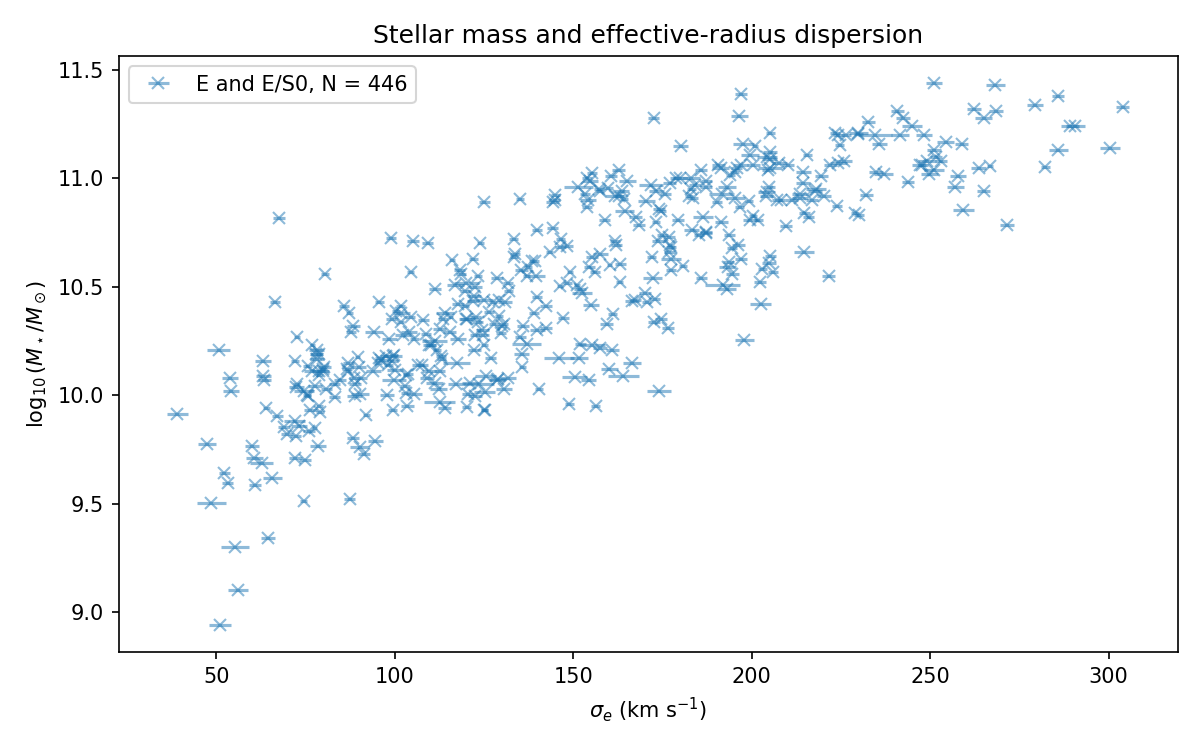

In [8]:
print('\n8) Look at the measurements')

# Show the measurements and their reported dispersion errors before fitting.
fig, ax = plt.subplots(figsize=(8, 5))
plt.errorbar(
    elliptical_data['sigma_re'],
    elliptical_data['mstar'],
    xerr=elliptical_data['sigma_re_err'],
    fmt='x',
    alpha=0.5,
    label=f'E and E/S0, N = {len(elliptical_data)}'
)
plt.title('Stellar mass and effective-radius dispersion')
plt.xlabel(r'$\sigma_e$ (km s$^{-1}$)')
plt.ylabel(r'$\log_{10}(M_\star/M_\odot)$')
plt.legend()
plt.tight_layout()
plt.show()


## 9) Fit the stellar-mass relation

I fit a straight line with logarithmic dispersion on the horizontal axis and logarithmic stellar mass on the vertical axis:

$$\log_{10}(M_\star/M_\odot)=a\log_{10}\!\left(\frac{\sigma_e}{\mathrm{km\,s^{-1}}}\right)+b.$$

The catalogue has already taken the logarithm of `mstar`, so I use that column directly. For dispersion, I apply the change-of-base identity using the tutorial's `np.log`:

$$\log_{10}x=\frac{\ln x}{\ln 10}.$$

`stats.linregress(x, y)` minimises squared vertical differences in logarithmic mass. Its standard errors describe this ordinary least-squares fit. They do not account for measurement errors in both axes or estimate intrinsic scatter. Those limits matter when interpreting how precise the fitted slope looks.

*Tutorial link: Tutorial 4, Worked Example: Linear Curve Fitting; Spotted Python Weeks 3–4, logarithms and arithmetic.*


In [9]:
print('\n9) Fit stellar mass against dispersion')

# Keep each dispersion paired with the mass from the same galaxy.
# mstar is already logarithmic; only the dispersion needs converting.
log_sigma = np.log(np.array(elliptical_data['sigma_re'])) / np.log(10)
log_mass = np.array(elliptical_data['mstar'])

mass_result = stats.linregress(log_sigma, log_mass)
print(f'log mass = ({mass_result.slope:.3f} +- {mass_result.stderr:.3f}) * log sigma + '
      f'({mass_result.intercept:.3f} +- {mass_result.intercept_stderr:.3f})')
print(f'R-value = {mass_result.rvalue:.3f}; p-value = {mass_result.pvalue:.3e}')



9) Fit stellar mass against dispersion
log mass = (2.139 +- 0.064) * log sigma + (5.931 +- 0.139)
R-value = 0.844; p-value = 2.679e-122


### Put the lecture comparison on the plot

The uploaded Week 3 Monday lecture, **PDF page 30**, shows the Oh et al. (2020) relation:

$$\log_{10}\sigma_e=0.285\log_{10}M_\star-0.845,$$

with dispersion in km/s and mass in solar masses. To draw that line on the current axes, I rearrange it to

$$\log_{10}M_\star=\frac{\log_{10}\sigma_e+0.845}{0.285}.$$

That rearranges the reference line. Comparing regression slopes also requires matching the fitting direction, which is the next step.

The reference comes from the supplied slide. It shows a bulge-to-total category that the uploaded tables do not reproduce, and it does not give the full fitting or uncertainty details. I keep those limits in mind when reading the two lines.



9, continued) Add the lecture comparison


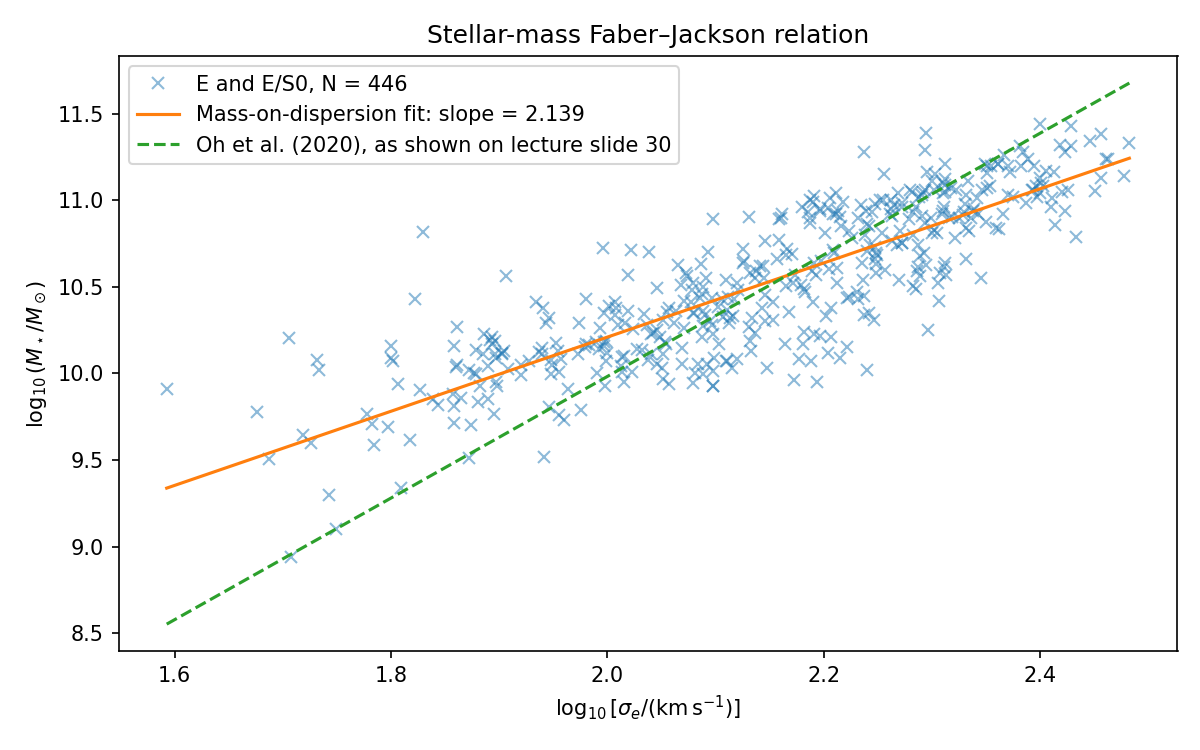

In [10]:
print('\n9, continued) Add the lecture comparison')

# Draw the lines across the dispersion range covered by the data.
# np.argmax gives a position; using -log_sigma finds the smallest value.
line_sigma = np.linspace(
    log_sigma[np.argmax(-log_sigma)],
    log_sigma[np.argmax(log_sigma)],
    200
)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(log_sigma, log_mass, 'x', alpha=0.5,
         label=f'E and E/S0, N = {len(log_mass)}')
plt.plot(line_sigma, mass_result.slope * line_sigma + mass_result.intercept,
         label=f'Mass-on-dispersion fit: slope = {mass_result.slope:.3f}')
plt.plot(line_sigma, (line_sigma + 0.845) / 0.285, '--',
         label='Oh et al. (2020), as shown on lecture slide 30')
plt.title('Stellar-mass Faber–Jackson relation')
plt.xlabel(r'$\log_{10}[\sigma_e/(\mathrm{km\,s^{-1}})]$')
plt.ylabel(r'$\log_{10}(M_\star/M_\odot)$')
plt.legend()
plt.tight_layout()
plt.show()


## 10) Compare slopes with the axes the same way round

Now I fit logarithmic dispersion against logarithmic mass and compare the new slope with 0.285. With scattered data, reversing a regression changes the quantity being minimised, so taking the reciprocal of the earlier slope would not do the same job.

The tutorial routine also returns a p-value for a zero-slope hypothesis. Agreement with the reference slope, or an explanation of galaxy formation, needs more evidence than that p-value provides.



10) Compare in the same fitting direction
log sigma = (0.333 +- 0.010) * log mass + (-1.360 +- 0.106)
Reference slope from the uploaded slide: 0.285
Measured slope minus reference slope: 0.048111189649393815


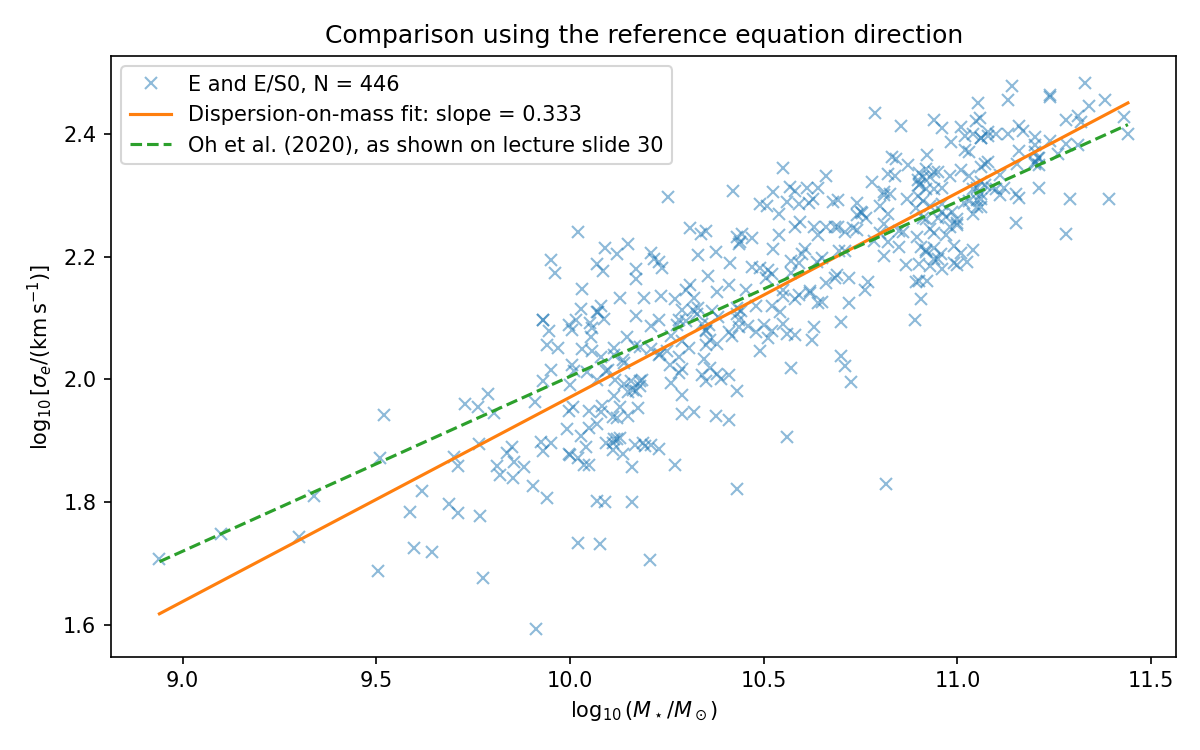

In [11]:
print('\n10) Compare in the same fitting direction')

# Swap the fitted axes explicitly to match the direction used on the slide.
comparison_result = stats.linregress(log_mass, log_sigma)
print(f'log sigma = ({comparison_result.slope:.3f} +- {comparison_result.stderr:.3f}) * log mass + '
      f'({comparison_result.intercept:.3f} +- {comparison_result.intercept_stderr:.3f})')
print('Reference slope from the uploaded slide:', 0.285)
print('Measured slope minus reference slope:', comparison_result.slope - 0.285)

line_mass = np.linspace(
    log_mass[np.argmax(-log_mass)],
    log_mass[np.argmax(log_mass)],
    200
)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(log_mass, log_sigma, 'x', alpha=0.5,
         label=f'E and E/S0, N = {len(log_mass)}')
plt.plot(line_mass, comparison_result.slope * line_mass + comparison_result.intercept,
         label=f'Dispersion-on-mass fit: slope = {comparison_result.slope:.3f}')
plt.plot(line_mass, 0.285 * line_mass - 0.845, '--',
         label='Oh et al. (2020), as shown on lecture slide 30')
plt.title('Comparison using the reference equation direction')
plt.xlabel(r'$\log_{10}(M_\star/M_\odot)$')
plt.ylabel(r'$\log_{10}[\sigma_e/(\mathrm{km\,s^{-1}})]$')
plt.legend()
plt.tight_layout()
plt.show()


## 11) Bring luminosity into the picture

The lecture summary on **PDF page 33** gives $L\propto\sigma^4$. So far, I have fitted stellar mass. The mass-to-light slides explain that the ratio depends on the stellar population, which is why I also look at the supplied r-band magnitudes.

I use the same straight-line routine to fit

$$M_r=c\log_{10}\!\left(\frac{\sigma_e}{\mathrm{km\,s^{-1}}}\right)+d.$$

Spotted Python Week 4 gives the magnitude–luminosity relation. Writing it as $M_r=C-2.5\log_{10}L_r$ puts the band-dependent zero point into $C$. Substituting the fitted line gives

$$L_r\propto\sigma_e^{\alpha_r},\qquad \alpha_r=-\frac{c}{2.5},\qquad s_{\alpha_r}=\frac{s_c}{2.5}.$$

This conversion uses algebra on the tutorial relation, so a solar r-band magnitude is not needed. The historical illustration on slide 30 uses **B-band** magnitude; these data use **r-band**. The exponent is useful for comparison, with that difference in measurement and sample kept in view.



11) Fit the magnitude relation
M_r = (-4.822 +- 0.165) * log sigma + (-10.600 +- 0.355)
r-band luminosity exponent = 1.929 +- 0.066
Lecture summary exponent: 4


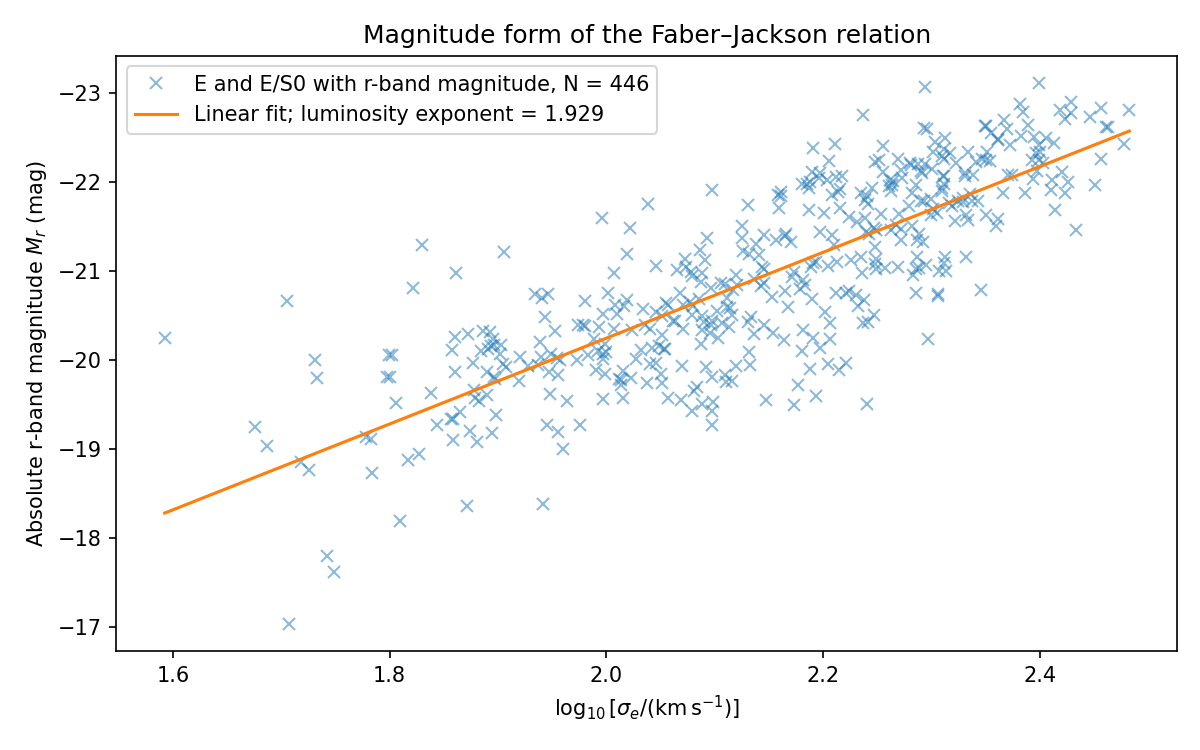

In [12]:
print('\n11) Fit the magnitude relation')

# Use galaxies with an r-band magnitude, then fit with the same routine.
magnitude_data = elliptical_data.dropna(subset=['m_r'])
magnitude_x = np.log(np.array(magnitude_data['sigma_re'])) / np.log(10)
magnitude_y = np.array(magnitude_data['m_r'])

magnitude_result = stats.linregress(magnitude_x, magnitude_y)
luminosity_exponent = -magnitude_result.slope / 2.5
luminosity_exponent_error = magnitude_result.stderr / 2.5

print(f'M_r = ({magnitude_result.slope:.3f} +- {magnitude_result.stderr:.3f}) * log sigma + '
      f'({magnitude_result.intercept:.3f} +- {magnitude_result.intercept_stderr:.3f})')
print(f'r-band luminosity exponent = {luminosity_exponent:.3f} +- {luminosity_exponent_error:.3f}')
print('Lecture summary exponent:', 4)

line_magnitude = np.linspace(
    magnitude_x[np.argmax(-magnitude_x)],
    magnitude_x[np.argmax(magnitude_x)],
    200
)
fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(magnitude_x, magnitude_y, 'x', alpha=0.5,
         label=f'E and E/S0 with r-band magnitude, N = {len(magnitude_data)}')
plt.plot(line_magnitude, magnitude_result.slope * line_magnitude + magnitude_result.intercept,
         label=f'Linear fit; luminosity exponent = {luminosity_exponent:.3f}')
plt.gca().invert_yaxis()
plt.title('Magnitude form of the Faber–Jackson relation')
plt.xlabel(r'$\log_{10}[\sigma_e/(\mathrm{km\,s^{-1}})]$')
plt.ylabel(r'Absolute r-band magnitude $M_r$ (mag)')
plt.legend()
plt.tight_layout()
plt.show()


## 12) Look at what the fitted line leaves behind

For each galaxy, I subtract the fitted logarithmic mass from the measured logarithmic mass:

$$r_i=y_i-(a x_i+b).$$

A positive residual puts the galaxy above the fitted line; a negative one puts it below. I look for curvature, changes in spread and isolated points. These differences help describe the fit, but do not by themselves measure intrinsic scatter. The sample stays fixed throughout this check.



12) Look at the residuals


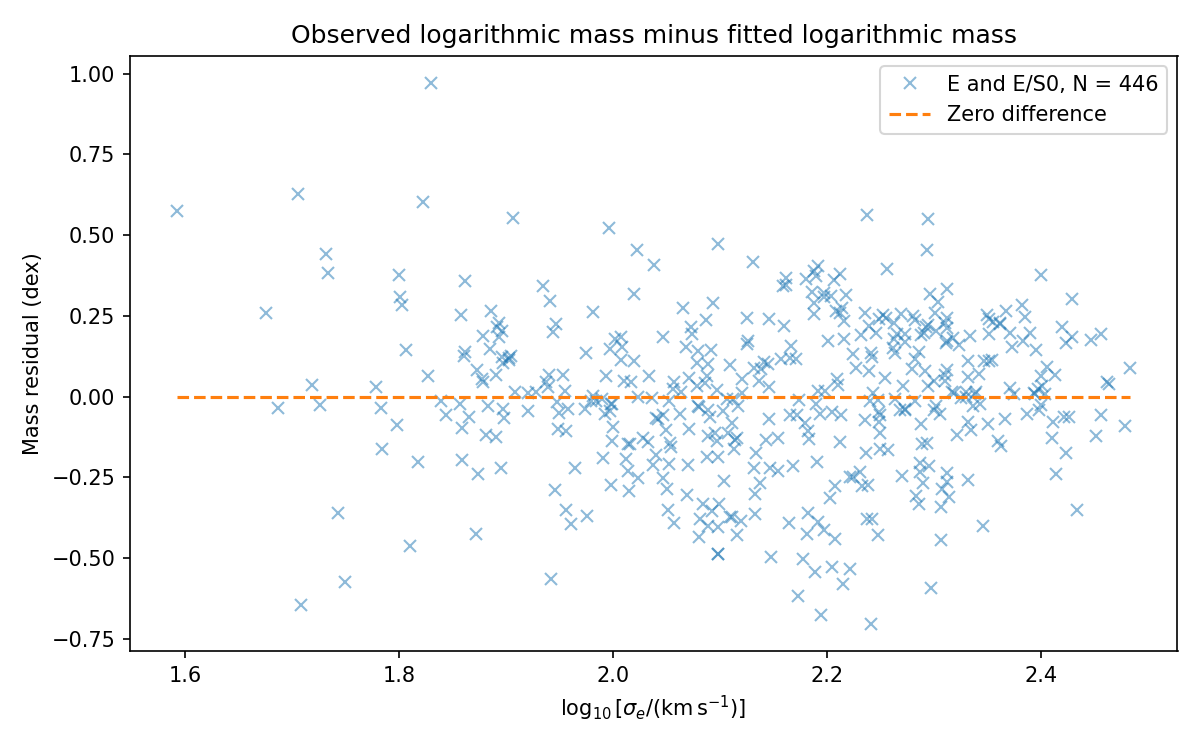

In [13]:
print('\n12) Look at the residuals')

# Measured minus fitted: positive residuals sit above the fitted line.
mass_prediction = mass_result.slope * log_sigma + mass_result.intercept
mass_residual = log_mass - mass_prediction

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(log_sigma, mass_residual, 'x', alpha=0.5,
         label=f'E and E/S0, N = {len(log_mass)}')
plt.plot(line_sigma, 0 * line_sigma, '--', label='Zero difference')
plt.title('Observed logarithmic mass minus fitted logarithmic mass')
plt.xlabel(r'$\log_{10}[\sigma_e/(\mathrm{km\,s^{-1}})]$')
plt.ylabel('Mass residual (dex)')
plt.legend()
plt.tight_layout()
plt.show()


## 13) See what changes when the morphology selection changes

Does including E/S0 galaxies matter? I repeat the mass-on-dispersion fit for strict ellipticals (`type == 0`) and compare it with the main E/E-S0 result. I also fit spirals, using codes 2, 2.5 and 3, as in Tutorial 4's separation of galaxy types.

The plot lets me see the populations and their fitted lines together. Their mass and dispersion ranges can differ, so a slope difference alone cannot isolate a formation mechanism. The strict-E galaxies also sit inside the main sample, which means those two fitted slopes are not independent.



13) Compare the morphology selections
Strict E: N = 230, slope = 2.124 +- 0.092
Spirals: N = 1053, slope = 3.115 +- 0.073


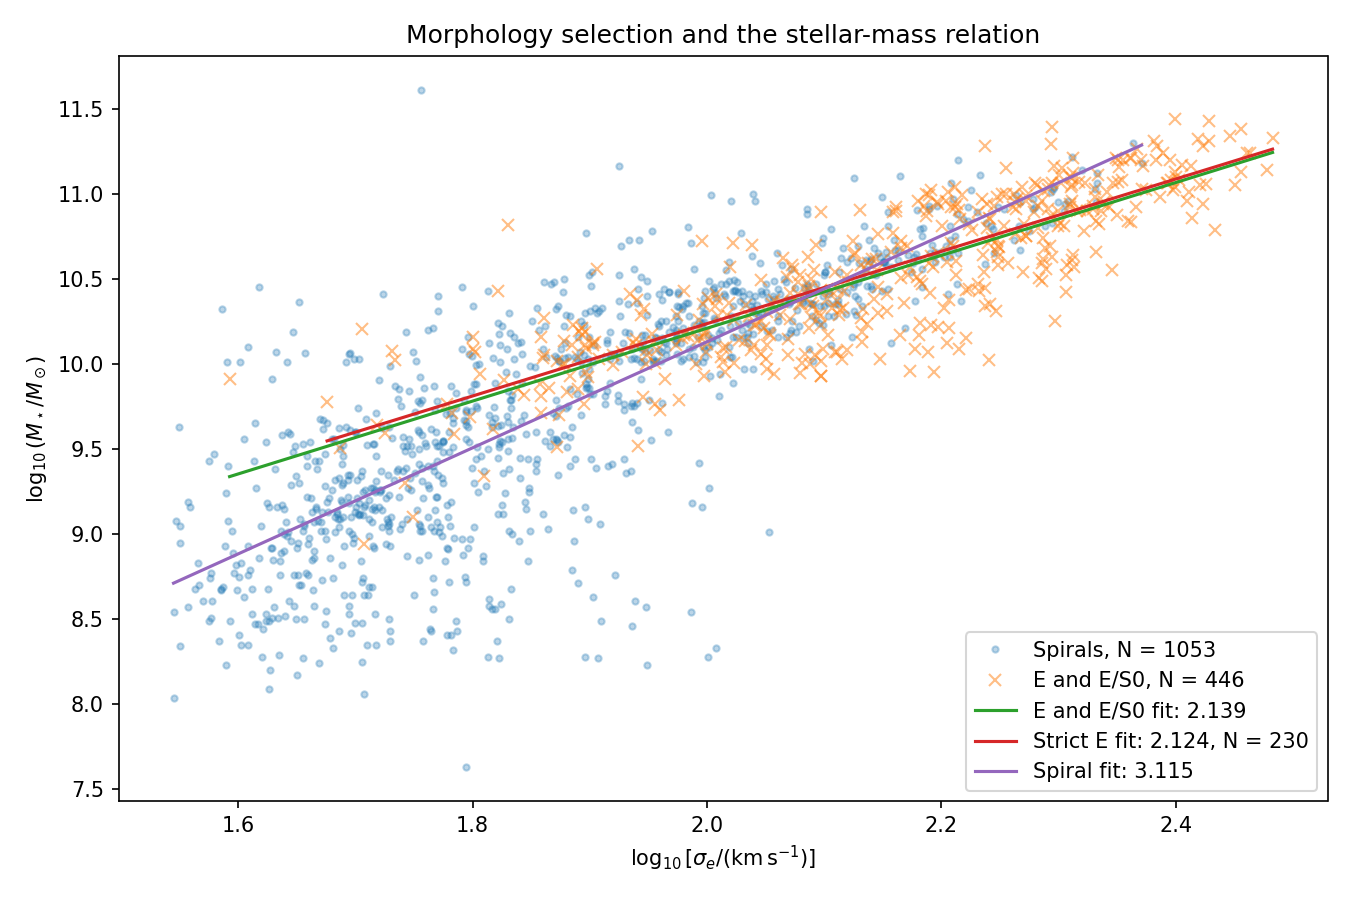

In [14]:
print('\n13) Compare the morphology selections')

# Repeat the same fit after changing only the morphology selection rule.
strict_e_data = zero_flag_data[zero_flag_data['type'] == 0]
spiral_data = zero_flag_data[
    (zero_flag_data['type'] >= 2) & (zero_flag_data['type'] <= 3)
]

strict_e_x = np.log(np.array(strict_e_data['sigma_re'])) / np.log(10)
strict_e_y = np.array(strict_e_data['mstar'])
spiral_x = np.log(np.array(spiral_data['sigma_re'])) / np.log(10)
spiral_y = np.array(spiral_data['mstar'])

strict_e_result = stats.linregress(strict_e_x, strict_e_y)
spiral_result = stats.linregress(spiral_x, spiral_y)

print(f'Strict E: N = {len(strict_e_data)}, slope = {strict_e_result.slope:.3f} +- {strict_e_result.stderr:.3f}')
print(f'Spirals: N = {len(spiral_data)}, slope = {spiral_result.slope:.3f} +- {spiral_result.stderr:.3f}')

line_strict_e = np.linspace(strict_e_x[np.argmax(-strict_e_x)], strict_e_x[np.argmax(strict_e_x)], 200)
line_spiral = np.linspace(spiral_x[np.argmax(-spiral_x)], spiral_x[np.argmax(spiral_x)], 200)

fig, ax = plt.subplots(figsize=(9, 6))
plt.plot(spiral_x, spiral_y, '.', alpha=0.3,
         label=f'Spirals, N = {len(spiral_data)}')
plt.plot(log_sigma, log_mass, 'x', alpha=0.5,
         label=f'E and E/S0, N = {len(elliptical_data)}')
plt.plot(line_sigma, mass_result.slope * line_sigma + mass_result.intercept,
         label=f'E and E/S0 fit: {mass_result.slope:.3f}')
plt.plot(line_strict_e, strict_e_result.slope * line_strict_e + strict_e_result.intercept,
         label=f'Strict E fit: {strict_e_result.slope:.3f}, N = {len(strict_e_data)}')
plt.plot(line_spiral, spiral_result.slope * line_spiral + spiral_result.intercept,
         label=f'Spiral fit: {spiral_result.slope:.3f}')
plt.title('Morphology selection and the stellar-mass relation')
plt.xlabel(r'$\log_{10}[\sigma_e/(\mathrm{km\,s^{-1}})]$')
plt.ylabel(r'$\log_{10}(M_\star/M_\odot)$')
plt.legend()
plt.tight_layout()
plt.show()


## 14) Same galaxies, different aperture

How much does the result depend on where the dispersion is measured? I compare the effective-radius and fixed 3 kpc apertures using **the same galaxies and the same observations**, with usable measurements in both apertures.

I refit both relations on this common sample. That keeps a change in sample membership from being mixed up with a change in aperture.

This extends the investigation using the same masks, logarithms, plots and `stats.linregress`. The fits share galaxies, so their separate standard errors are not a formal significance test of the slope difference.



14) Compare apertures on the same galaxies
Galaxies with both aperture measurements: 446
Re slope = 2.139 +- 0.064
3 kpc slope = 2.105 +- 0.059
3 kpc slope minus Re slope: -0.034450772120269146


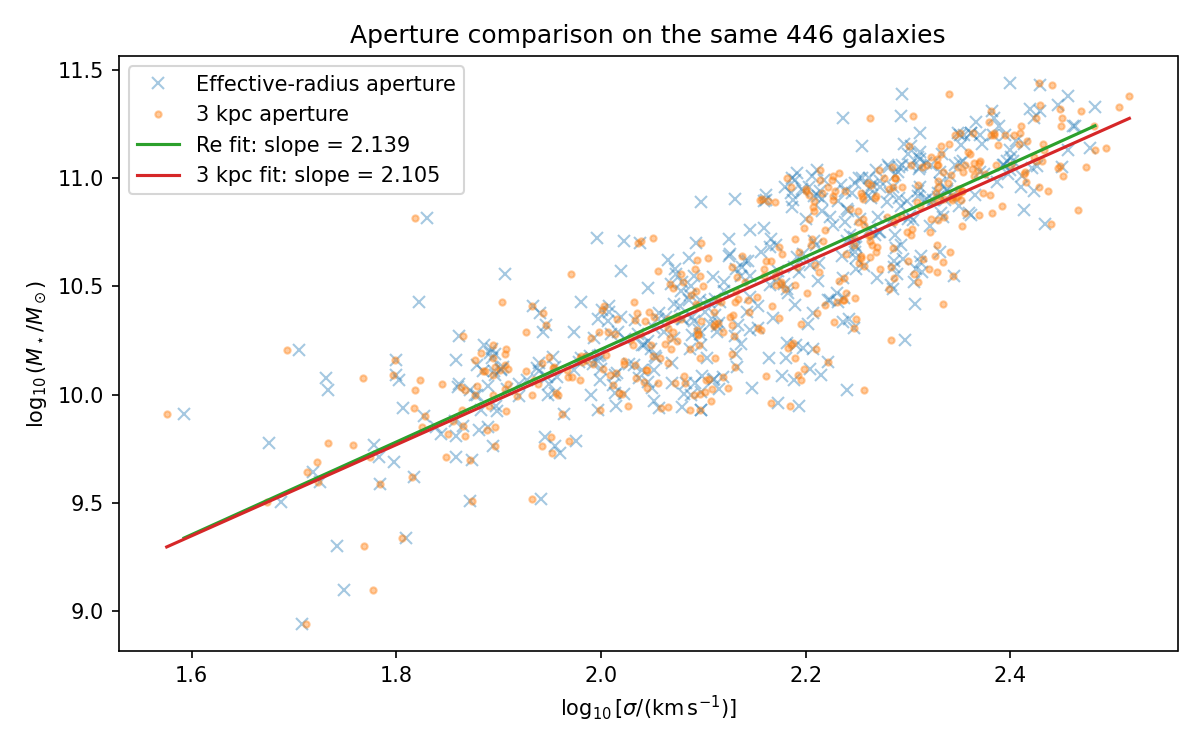

In [15]:
print('\n14) Compare apertures on the same galaxies')

# Keep a common sample with both aperture measurements and positive errors.
common_aperture_data = elliptical_data.dropna(
    subset=['sigma_3kpc_round', 'sigma_3kpc_round_err']
)
common_aperture_data = common_aperture_data[
    (common_aperture_data['sigma_3kpc_round'] > 0) &
    (common_aperture_data['sigma_3kpc_round_err'] > 0)
]

common_mass = np.array(common_aperture_data['mstar'])
common_re = np.log(np.array(common_aperture_data['sigma_re'])) / np.log(10)
common_3kpc = np.log(np.array(common_aperture_data['sigma_3kpc_round'])) / np.log(10)

aperture_re_result = stats.linregress(common_re, common_mass)
aperture_3kpc_result = stats.linregress(common_3kpc, common_mass)

print('Galaxies with both aperture measurements:', len(common_aperture_data))
print(f'Re slope = {aperture_re_result.slope:.3f} +- {aperture_re_result.stderr:.3f}')
print(f'3 kpc slope = {aperture_3kpc_result.slope:.3f} +- {aperture_3kpc_result.stderr:.3f}')
print('3 kpc slope minus Re slope:', aperture_3kpc_result.slope - aperture_re_result.slope)

line_re = np.linspace(common_re[np.argmax(-common_re)], common_re[np.argmax(common_re)], 200)
line_3kpc = np.linspace(common_3kpc[np.argmax(-common_3kpc)], common_3kpc[np.argmax(common_3kpc)], 200)

fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(common_re, common_mass, 'x', alpha=0.4, label='Effective-radius aperture')
plt.plot(common_3kpc, common_mass, '.', alpha=0.4, label='3 kpc aperture')
plt.plot(line_re, aperture_re_result.slope * line_re + aperture_re_result.intercept,
         label=f'Re fit: slope = {aperture_re_result.slope:.3f}')
plt.plot(line_3kpc, aperture_3kpc_result.slope * line_3kpc + aperture_3kpc_result.intercept,
         label=f'3 kpc fit: slope = {aperture_3kpc_result.slope:.3f}')
plt.title(f'Aperture comparison on the same {len(common_aperture_data)} galaxies')
plt.xlabel(r'$\log_{10}[\sigma/(\mathrm{km\,s^{-1}})]$')
plt.ylabel(r'$\log_{10}(M_\star/M_\odot)$')
plt.legend()
plt.tight_layout()
plt.show()


## 15) Return to the flag choice

Earlier, I kept `bad_class == 0` as a working rule. Here I repeat the main fit with all flag codes included, using `mass_data` from before that cut.

This shows how much the choice affects these particular data. The meaning of the flag codes still needs confirmation, even if the fitted slope changes very little.


In [16]:
print('\n15) Check the flag selection')

# Go back to the sample before the zero-flag cut and repeat the main fit.
elliptical_all_flags = mass_data[
    (mass_data['type'] == 0) | (mass_data['type'] == 0.5)
]
all_flags_x = np.log(np.array(elliptical_all_flags['sigma_re'])) / np.log(10)
all_flags_y = np.array(elliptical_all_flags['mstar'])
all_flags_result = stats.linregress(all_flags_x, all_flags_y)

print('Flag codes before the zero-flag selection:')
print(elliptical_all_flags['bad_class'].value_counts())
print(f'All flag codes: N = {len(elliptical_all_flags)}, slope = {all_flags_result.slope:.3f} +- {all_flags_result.stderr:.3f}')
print(f'Zero flag only: N = {len(elliptical_data)}, slope = {mass_result.slope:.3f} +- {mass_result.stderr:.3f}')



15) Check the flag selection
Flag codes before the zero-flag selection:
bad_class
0    446
8      1
Name: count, dtype: int64
All flag codes: N = 447, slope = 2.138 +- 0.064
Zero flag only: N = 446, slope = 2.139 +- 0.064


## 16) Save the numbers so the analysis can be followed

The plots show the trends; these tables keep the selections, galaxy IDs, cube IDs, fitted values and residuals available to inspect. I save them into the supplied `results/` folder with Tutorial 2's `to_csv(..., index=False)`.

Running the notebook updates its inline outputs and these CSVs. The separate PNGs and `run_log.txt` are snapshots, so they need updating separately if the analysis changes. Figure saving is kept outside the analysis because `savefig` was not verified in the supplied tutorials.


In [17]:
print('\n16) Save the results')

# Put the fits in a consistent order, with the sample size beside each one.
fit_names = ['Main stellar mass on dispersion',
             'Reference-direction dispersion on stellar mass',
             'r-band magnitude on dispersion',
             'Strict ellipticals: stellar mass on dispersion',
             'Spirals: stellar mass on dispersion',
             'Common aperture sample: stellar mass on Re dispersion',
             'Common aperture sample: stellar mass on 3 kpc dispersion',
             'All flag codes: stellar mass on dispersion']
fit_results = [mass_result, comparison_result, magnitude_result,
               strict_e_result, spiral_result, aperture_re_result,
               aperture_3kpc_result, all_flags_result]
fit_sizes = [len(elliptical_data), len(elliptical_data), len(magnitude_data),
             len(strict_e_data), len(spiral_data), len(common_aperture_data),
             len(common_aperture_data), len(elliptical_all_flags)]

fit_rows = []
for i in range(len(fit_results)):
    result = fit_results[i]
    fit_rows.append({
        'fit': fit_names[i],
        'N_galaxies': fit_sizes[i],
        'slope': result.slope,
        'slope_standard_error': result.stderr,
        'intercept': result.intercept,
        'intercept_standard_error': result.intercept_stderr,
        'r_value': result.rvalue,
        'p_value_zero_slope': result.pvalue
    })

fit_summary = pd.DataFrame(fit_rows)
print(fit_summary)

residual_table = pd.DataFrame({
    'catid': np.array(elliptical_data['catid']),
    'cubeidpub': np.array(elliptical_data['cubeidpub']),
    'log10_sigma_re_km_s': log_sigma,
    'log10_stellar_mass_solar': log_mass,
    'predicted_log10_stellar_mass': mass_prediction,
    'mass_residual_dex': mass_residual
})

exponent_table = pd.DataFrame({
    'band': ['r'],
    'N_galaxies': [len(magnitude_data)],
    'luminosity_exponent': [luminosity_exponent],
    'exponent_standard_error': [luminosity_exponent_error],
    'lecture_summary_exponent': [4]
})

observation_audit.to_csv('results/observation_audit.csv', index=False)
matching_audit.to_csv('results/matching_audit.csv', index=False)
sample_audit.to_csv('results/galaxy_sample_audit.csv', index=False)
selection_counts.to_csv('results/selection_counts.csv', index=False)
elliptical_data.to_csv('results/selected_galaxies.csv', index=False)
common_aperture_data.to_csv('results/common_aperture_galaxies.csv', index=False)
fit_summary.to_csv('results/fit_summary.csv', index=False)
residual_table.to_csv('results/mass_residuals.csv', index=False)
exponent_table.to_csv('results/luminosity_exponent.csv', index=False)

print('Finished saving the results and sample records.')



16) Save the results
                                                 fit  ...  p_value_zero_slope
0                    Main stellar mass on dispersion  ...       2.678931e-122
1     Reference-direction dispersion on stellar mass  ...       2.678931e-122
2                     r-band magnitude on dispersion  ...       2.333420e-105
3     Strict ellipticals: stellar mass on dispersion  ...        2.346032e-61
4                Spirals: stellar mass on dispersion  ...       4.044317e-233
5  Common aperture sample: stellar mass on Re dis...  ...       2.678931e-122
6  Common aperture sample: stellar mass on 3 kpc ...  ...       2.137586e-133
7         All flag codes: stellar mass on dispersion  ...       1.215769e-122

[8 rows x 8 columns]
Finished saving the results and sample records.


## 17) What does this run tell us?

The main selection leaves **446 galaxies**. The stellar-mass fit gives a slope of **2.139 ± 0.064**. Fitting in the lecture reference's direction gives **0.333 ± 0.010**, compared with the slide's 0.285. The magnitude fit gives an r-band luminosity exponent of **1.929 ± 0.066**, compared with the lecture summary's exponent of 4.

There is a rising mass–dispersion trend in this sample. Before attaching a physical explanation to the exact slope, I need to consider how the galaxies were selected, how dispersion was measured and what the fitting method assumes. The morphology, aperture and flag comparisons make some of those choices visible.

The main limits are:

- The trend describes an association between stellar mass and stellar motions. Several lines on a plot cannot establish a unique formation history.
- Stellar mass and luminosity depend on the mass-to-light ratio. The historical B-band illustration and this r-band fit also use different measurements.
- Changing morphology changes the population, including its mass and dispersion ranges. The aperture fits share the same galaxies and are correlated.
- Missing effective-radius measurements leave an incomplete sample. Selection and measurement effects may influence the slope.
- The zero-flag rule is explicit, but the individual flag definitions are still missing.
- Ordinary least squares does not account for errors in both axes or estimate intrinsic scatter. Its coefficient errors are only part of the uncertainty.
- The lecture supplies a reference equation, with limited information about the reference sample and fitting method.

These numbers describe the supplied run. After changing data or selections, use the new outputs and update this paragraph and `RESULTS.md` as well.

A useful next step within the same programming tools would be to inspect unusual objects in the saved tables or repeat the comparison with another **documented** dispersion definition. Extending the fitting method or literature comparison would need sources beyond those supplied here.

Meeting records, commits, the individual reflection and the group recording are separate parts of the assessment and need to reflect the group's actual work.
